# TPE · EPA Fuel Economy 2025
## 1. Análisis exploratorio inicial

Se examinan la estructura, los atributos, las distribuciones, los valores faltantes y los valores extremos de la base. El objetivo es comprender los datos antes de realizar la limpieza y plantear las hipótesis.

### Contexto y lectura de los datos

El conjunto contiene resultados de tests de vehículos de año modelo 2025 realizados por la Environmental Protection Agency (EPA) de Estados Unidos y por fabricantes que reportan sus resultados al organismo. Estos tests forman parte del proceso de determinación de las estimaciones oficiales de economía de combustible.

Se lee la hoja `Sheet1` del Excel original, conservado en `data/`. Se muestran las primeras filas y un resumen de las columnas para comprobar que la lectura sea correcta.



In [3]:
import os
import pandas as pd

archivo = "data/25-testcar-2026-01-21.xlsx"
datos = pd.read_excel(archivo, sheet_name='Sheet1')

print('Filas:', datos.shape[0], '| Columnas:', datos.shape[1])
display(datos.head())
datos.info()

Filas: 4287 | Columnas: 67


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


<class 'pandas.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   str    
 2   Veh Mfr Code                    4287 non-null   str    
 3   Represented Test Veh Make       4287 non-null   str    
 4   Represented Test Veh Model      4287 non-null   str    
 5   Test Vehicle ID                 4287 non-null   str    
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   str    
 9   Vehicle Type                    4287 non-null   str    
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     4287 non-null

### Caracterización de los atributos

- Model Year — Temporal discreta: representa el año modelo, expresado en años enteros.
- Vehicle Manufacturer Name — Nominal: distingue fabricantes sin establecer un orden.
- Veh Mfr Code — Nominal: identifica al fabricante mediante un código.
- Represented Test Veh Make — Nominal: distingue marcas sin establecer un orden.
- Represented Test Veh Model — Nominal: identifica modelos de vehículos.
- Test Vehicle ID — Nominal: identifica vehículos; sus valores no representan cantidades.
- Test Veh Configuration # — Nominal: identifica configuraciones; el número funciona como una etiqueta.
- Test Veh Displacement (L) — Cuantitativa continua: mide un volumen que puede expresarse con decimales.
- Actual Tested Testgroup — Nominal: identifica grupos de test sin un orden numérico.
- Vehicle Type — Nominal: clasifica los vehículos en categorías sin jerarquía.
- Rated Horsepower — Cuantitativa continua: representa una medida de potencia, aunque se registre con números enteros.
- "#" of Cylinders and Rotors — Cuantitativa discreta: cuenta cilindros o rotores en unidades enteras.
- Engine Code — Nominal: identifica motores mediante códigos.
- Tested Transmission Type Code — Nominal: codifica categorías de transmisión.
- Tested Transmission Type — Nominal: distingue tipos de transmisión sin establecer un orden.
- "#" of Gears — Cuantitativa discreta: cuenta marchas en unidades enteras.
- Transmission Lockup? — Nominal binaria: indica dos posibilidades, presencia o ausencia.
- Drive System Code — Nominal: identifica categorías de tracción mediante códigos.
- Drive System Description — Nominal: distingue sistemas de tracción sin una jerarquía.
- Transmission Overdrive Code — Nominal: representa categorías mediante códigos, no cantidades.
- Transmission Overdrive Desc — Nominal: describe condiciones de sobremarcha sin establecer un orden.
- Equivalent Test Weight (lbs.) — Cuantitativa continua: representa una medida de peso, aunque se utilicen valores estandarizados.
- Axle Ratio — Cuantitativa continua: expresa una relación mecánica que admite decimales.
- N/V Ratio — Cuantitativa continua: expresa una relación entre magnitudes, no un conteo.
- Shift Indicator Light Use Cd — Nominal: codifica categorías de presencia y uso del indicador.
- Shift Indicator Light Use Desc — Nominal: describe categorías de presencia y uso sin un orden.
- Test Number — Nominal: identifica tests; no representa una cantidad.
- Test Originator — Nominal: distingue el origen del test sin establecer un orden.
- Analytically Derived FE? — Nominal binaria: indica si se utilizó o no el método analítico.
- ADFE Test Number — Nominal: identifica el test asociado al cálculo analítico.
- ADFE Total Road Load HP — Cuantitativa continua: representa una medida de potencia.
- ADFE Equiv. Test Weight (lbs.) — Cuantitativa continua: representa una medida de peso.
- ADFE N/V Ratio — Cuantitativa continua: expresa una relación mecánica que admite decimales.
- Test Procedure Cd — Nominal: identifica procedimientos mediante códigos.
- Test Procedure Description — Nominal: distingue procedimientos sin una jerarquía.
- Test Fuel Type Cd — Nominal: codifica tipos de combustible o fuentes de energía.
- Test Fuel Type Description — Nominal: distingue combustibles o fuentes de energía sin un orden.
- Test Category — Nominal: agrupa los tests en categorías sin jerarquía.
- THC (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- CO (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- CO2 (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- NOx (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- PM (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- CH4 (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- N2O (g/mi) — Cuantitativa continua: mide una cantidad de emisiones por distancia.
- RND_ADJ_FE — Cuantitativa continua: mide la distancia recorrida por unidad de combustible.
- FE_UNIT — Nominal: indica una unidad de medida, no una cantidad.
- FE Bag 1 — Cuantitativa continua: mide la economía de combustible de una fase del test.
- FE Bag 2 — Cuantitativa continua: mide la economía de combustible de una fase del test.
- FE Bag 3 — Cuantitativa continua: mide la economía de combustible de una fase del test.
- FE Bag 4 — Cuantitativa continua: mide la economía de combustible de una fase del test.
- DT-Inertia Work Ratio Rating — Cuantitativa continua: representa una medida numérica de evaluación, no un conteo.
- DT-Absolute Speed Change Ratg — Cuantitativa continua: representa una medida numérica de evaluación, no una categoría.
- DT-Energy Economy Rating — Cuantitativa continua: representa una medida numérica de evaluación que admite decimales.
- Target Coef A (lbf) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Target Coef B (lbf/mph) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Target Coef C (lbf/mph**2) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Set Coef A (lbf) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Set Coef B (lbf/mph) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Set Coef C (lbf/mph**2) — Cuantitativa continua: es un coeficiente numérico que admite decimales.
- Aftertreatment Device Cd — Nominal: identifica tipos de dispositivos mediante códigos.
- Aftertreatment Device Desc — Nominal: distingue dispositivos sin establecer un orden.
- Police - Emergency Vehicle? — Nominal binaria: indica dos posibilidades, uso policial o de emergencia y ausencia de ese uso.
- Averaging Group ID — Nominal: identifica grupos de promediado mediante etiquetas.
- Averaging Weighting Factor — Cuantitativa continua: expresa un peso numérico utilizado en el cálculo de un promedio.
- Averaging Method Cd — Nominal: identifica métodos de promediado mediante códigos.
- Averging Method Desc — Nominal: distingue métodos de promediado sin establecer un orden.

### Unidad de observación y repeticiones

Cada fila de la base corresponde a un registro de ensayo asociado a una configuración de vehículo. Una misma configuración puede aparecer en varios registros debido a diferencias en los procedimientos de prueba, combustibles u otras condiciones del ensayo.
Según los metadatos, la combinación de Veh Mfr Code, Test Vehicle ID y Test Veh Configuration # identifica una configuración de vehículo de ensayo. En consecuencia, la cantidad de filas no equivale necesariamente a la cantidad de configuraciones distintas.
Esta distinción se tendrá en cuenta al identificar posibles duplicados, calcular estadísticas y evaluar las hipótesis. Las repeticiones se examinarán antes de decidir si corresponde conservarlas, seleccionar determinados ensayos o agrupar resultados. Para cada análisis se explicitarán las condiciones consideradas y la unidad sobre la que se obtienen las conclusiones.

In [4]:
# Según los metadatos, estas columnas identifican una configuración.
clave_configuracion = [
    "Veh Mfr Code",
    "Test Vehicle ID",
    "Test Veh Configuration #"
]

# 1. Comparamos la cantidad de registros con las configuraciones distintas.
cantidad_registros = datos.shape[0]

configuraciones = datos[clave_configuracion].drop_duplicates()
cantidad_configuraciones = configuraciones.shape[0]

print("Cantidad de registros:", cantidad_registros)
print("Cantidad de configuraciones distintas:", cantidad_configuraciones)

# 2. Distinguimos filas idénticas de configuraciones repetidas.
# duplicated() considera todas las columnas por defecto.
print(
    "Filas completamente duplicadas:",
    datos.duplicated().sum()
)

# keep=False marca todas las apariciones de una configuración repetida.
configuracion_repetida = datos.duplicated(
    subset=clave_configuracion,
    keep=False
)

cantidad_configuraciones_repetidas = (
    datos.loc[configuracion_repetida, clave_configuracion]
    .drop_duplicates()
    .shape[0]
)

print(
    "Configuraciones presentes en más de un registro:",
    cantidad_configuraciones_repetidas
)

# 3. Mostramos un ejemplo concreto presente en esta base.
# Filtramos por la clave completa para seleccionar una sola configuración.
ejemplo = datos[
    (datos["Veh Mfr Code"] == "ASX")
    & (datos["Test Vehicle ID"] == "5723PT5601")
    & (datos["Test Veh Configuration #"] == 0)
]

columnas_comparacion = clave_configuracion + [
    "Represented Test Veh Model",
    "Test Number",
    "Test Procedure Description",
    "Test Category",
    "Test Fuel Type Description",
    "RND_ADJ_FE"
]

display(
    ejemplo[columnas_comparacion]
    .sort_values(by=["Test Category", "Test Number"])
)

Cantidad de registros: 4287
Cantidad de configuraciones distintas: 1448
Filas completamente duplicadas: 0
Configuraciones presentes en más de un registro: 1293


,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Represented Test Veh Model,Test Number,Test Procedure Description,Test Category,Test Fuel Type Description,RND_ADJ_FE
0,ASX,5723PT5601,0,DB12 V8,RASX10082337,Federal fuel 2-day exhaust (w/can load),FTP,Tier 2 Cert Gasoline,18.3
1,ASX,5723PT5601,0,DB12 V8,RASX10082338,HWFE,HWY,Tier 2 Cert Gasoline,31.3


La cantidad de registros supera la cantidad de configuraciones distintas, lo que muestra que algunas configuraciones aparecen en múltiples filas. En el ejemplo presentado, una misma configuración tiene registros correspondientes a las categorías FTP y HWY, con diferentes resultados de economía de combustible

### Valores Nulos

Se analiza la presencia de valores faltantes para evaluar la disponibilidad de información en cada atributo. Se calcula su cantidad y su porcentaje respecto del total de registros, y luego se examinan algunos patrones según las características del ensayo.
Esta distinción es necesaria porque un valor ausente puede corresponder a información no registrada o a un atributo que no resulta aplicable a determinado ensayo. En esta etapa se identifican y describen los faltantes; su tratamiento se abordará durante la limpieza.

In [25]:
# 1. Valores faltantes reconocidos por Pandas.
cantidad_nulos = datos.isna().sum()

resumen_nulos = pd.DataFrame({
    "Cantidad de nulos": cantidad_nulos,
    "Porcentaje de nulos": cantidad_nulos / datos.shape[0] * 100
}).sort_values(by="Cantidad de nulos", ascending=False)

display(
    resumen_nulos[resumen_nulos["Cantidad de nulos"] > 0].round(2)
)

print("Atributos con nulos:", (cantidad_nulos > 0).sum())
print(
    "Filas con al menos un nulo:",
    (datos.isna().sum(axis=1) > 0).sum()
)
print("Total de filas:", datos.shape[0])


# 2. Posibles representaciones alternativas de valores faltantes.
# Se ignoran las diferencias de mayúsculas y los espacios exteriores.
marcadores_texto = [
    "", "-", "--", "?", "na", "n/a", "nan", "none", "null",
    "unknown", "missing", "not available", "not applicable", "-1"
]

posibles_faltantes = {}

for columna in datos.columns:
    valores = datos[columna]

    if valores.dtype == "object":
        valores = valores.str.strip().str.lower()
        cantidad = valores.isin(marcadores_texto).sum()
    else:
        cantidad = (valores == -1).sum()

    posibles_faltantes[columna] = cantidad

resumen_marcadores = pd.DataFrame.from_dict(
    posibles_faltantes,
    orient="index",
    columns=["Posibles marcadores de faltantes"]
)

resumen_marcadores = resumen_marcadores[
    resumen_marcadores["Posibles marcadores de faltantes"] > 0
].sort_values(by="Posibles marcadores de faltantes", ascending=False)

display(resumen_marcadores)

,Cantidad de nulos,Porcentaje de nulos
Averaging Weighting Factor,4212,98.25
Averaging Group ID,4212,98.25
ADFE Test Number,4075,95.05
ADFE N/V Ratio,4075,95.05
ADFE Total Road Load HP,4075,95.05
ADFE Equiv. Test Weight (lbs.),4075,95.05
FE Bag 4,3899,90.95
PM (g/mi),3898,90.93
FE Bag 3,2834,66.11
FE Bag 2,2423,56.52


Atributos con nulos: 24
Filas con al menos un nulo: 4287
Total de filas: 4287


,Posibles marcadores de faltantes
DT-Absolute Speed Change Ratg,6
DT-Inertia Work Ratio Rating,5
DT-Energy Economy Rating,2


### Examinar un caso donde el contexto explica los faltantes: ADFE

Los cuatro campos ADFE se relacionan con la economía de combustible derivada analíticamente. Podemos contrastar su disponibilidad con el indicador Analytically Derived FE?

In [24]:
columnas_adfe = [
    "ADFE Test Number",
    "ADFE Total Road Load HP",
    "ADFE Equiv. Test Weight (lbs.)",
    "ADFE N/V Ratio"
]

for respuesta in datos["Analytically Derived FE?"].unique():
    grupo = datos[
        datos["Analytically Derived FE?"] == respuesta
    ]

    print("Analytically Derived FE?:", respuesta)
    print("Cantidad de registros:", grupo.shape[0])

    display(grupo[columnas_adfe].isna().sum())

Analytically Derived FE?: No
Cantidad de registros: 4075


ADFE Test Number                  4075
ADFE Total Road Load HP           4075
ADFE Equiv. Test Weight (lbs.)    4075
ADFE N/V Ratio                    4075
dtype: int64

Analytically Derived FE?: Yes
Cantidad de registros: 212


ADFE Test Number                  0
ADFE Total Road Load HP           0
ADFE Equiv. Test Weight (lbs.)    0
ADFE N/V Ratio                    0
dtype: int64

La ausencia de información en los campos ADFE coincide con los registros que no presentan economía de combustible derivada analíticamente. Este patrón es consistente con atributos que no resultan aplicables a esos registros, en lugar de una pérdida general de información. Por ello, su elevado porcentaje de faltantes no es suficiente, por sí solo, para justificar su eliminación o imputación.

Se encontraron valores faltantes en 24 de los 67 atributos. Su proporción varía entre columnas: por ejemplo, ADFE Test Number presenta un 95,05 % de faltantes, mientras que RND_ADJ_FE presenta un 5,16 %.

Se cuantificaron los valores faltantes reconocidos por Pandas y se buscaron posibles representaciones alternativas de ausencia de información. Los valores encontrados en esta segunda revisión se consideran candidatos a inspeccionar, sin clasificarlos automáticamente como nulos ni modificar la base, ya que su interpretación depende del significado de cada atributo.

## Exploración de las distribuciones

El conjunto de datos reúne resultados de ensayos de vehículos e incluye información sobre sus características técnicas, las pruebas realizadas y las mediciones obtenidas. 

Se seleccionan cinco variables que permiten cubrir distintos aspectos de la información disponible. Se combinan atributos cuantitativos y categóricos para describir tanto la variabilidad de las mediciones como la presencia de diferentes grupos de registros.

- Rated Horsepower: Se selecciona para incorporar las diferencias de potencia entre los vehículos ensayados y conocer la diversidad de prestaciones representadas en la base.
- Equivalent Test Weight (lbs.): Se incluye para complementar la descripción técnica con el peso considerado en las pruebas, incorporando una dimensión diferente de la potencia.
- RND_ADJ_FE: Se elige para incluir una medición obtenida en los ensayos. Así, la exploración contempla los resultados registrados, además de las características técnicas de los vehículos.
- Test Fuel Type Description: Se incorpora para conocer la composición de la base según el combustible utilizado y observar si los registros se concentran en determinados grupos.
- Test Category: Se selecciona para reconocer la variedad de ensayos presentes y su representación en la base, evitando interpretar el conjunto como si todos los registros correspondieran al mismo tipo de prueba.



Se exploran las distribuciones de potencia, peso equivalente de ensayo y economía de combustible mediante estadísticos descriptivos, histogramas y diagramas de caja.
Los histogramas permiten observar la concentración y dispersión de los valores. Los diagramas de caja complementan esta descripción señalando posibles valores atípicos mediante el criterio de 1,5 veces el rango intercuartílico: valores inferiores a Q1 − 1,5 × RIC o superiores a Q3 + 1,5 × RIC, donde RIC = Q3 − Q1.
Los faltantes se omiten únicamente para los cálculos y gráficos, sin modificar la base.

count    4287.00
mean      340.70
std       175.12
min         1.00
25%       201.00
50%       305.00
75%       409.00
max      1948.00
Name: Rated Horsepower, dtype: float64

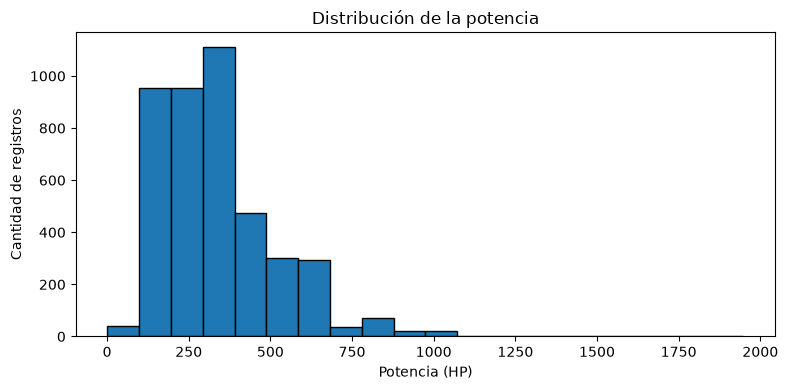

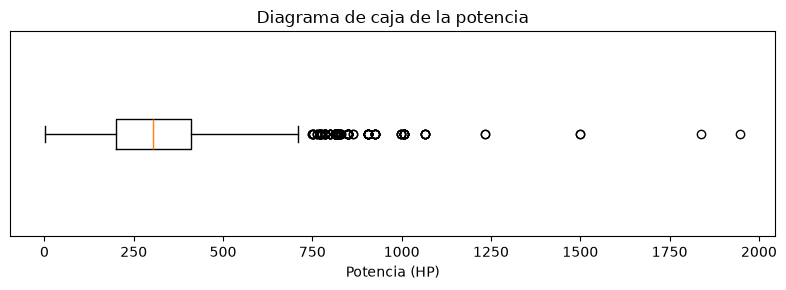

In [15]:
import matplotlib.pyplot as plt

potencia = datos["Rated Horsepower"].dropna()

display(potencia.describe().round(2))

plt.figure(figsize=(8, 4))
plt.hist(potencia, bins=20, edgecolor="black")
plt.title("Distribución de la potencia")
plt.xlabel("Potencia (HP)")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.boxplot(potencia, orientation="horizontal", whis=1.5)
plt.title("Diagrama de caja de la potencia")
plt.xlabel("Potencia (HP)")
plt.yticks([])
plt.tight_layout()
plt.show()

### Análisis de la potencia

La potencia presenta una mediana de 305 HP, con el 50 % central de los registros entre 201 y 409 HP. La media, de 340,70 HP, supera a la mediana, en consonancia con la presencia de valores elevados que extienden la distribución hacia la derecha.
Según el criterio del diagrama de caja, el límite superior es 721 HP. Los registros que superan ese valor se señalan como posibles atípicos, y el máximo observado alcanza 1948 HP. Podrían corresponder a vehículos de altas prestaciones, aunque esto requiere revisar los registros antes de determinar su validez.
El mínimo de 1 HP también merece revisión por su significado, aunque no quede señalado como atípico por este criterio. Esto muestra que el boxplot debe complementarse con la interpretación del atributo.

count    4287.00
mean     4818.78
std       985.82
min      2750.00
25%      4000.00
50%      4750.00
75%      5500.00
max      9000.00
Name: Equivalent Test Weight (lbs.), dtype: float64

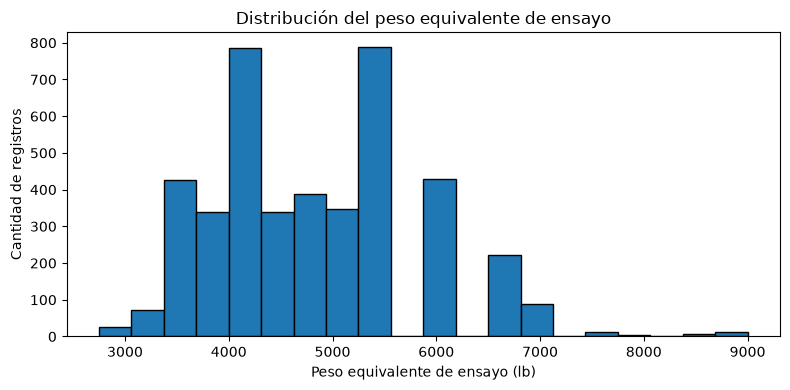

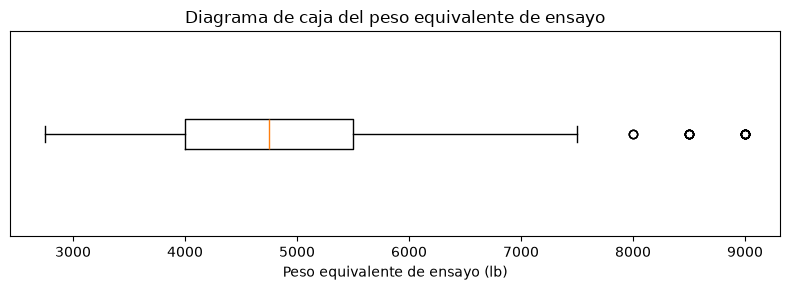

In [16]:
peso = datos["Equivalent Test Weight (lbs.)"].dropna()

display(peso.describe().round(2))

plt.figure(figsize=(8, 4))
plt.hist(peso, bins=20, edgecolor="black")
plt.title("Distribución del peso equivalente de ensayo")
plt.xlabel("Peso equivalente de ensayo (lb)")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.boxplot(peso, orientation="horizontal", whis=1.5)
plt.title("Diagrama de caja del peso equivalente de ensayo")
plt.xlabel("Peso equivalente de ensayo (lb)")
plt.yticks([])
plt.tight_layout()
plt.show()

### Análisis del peso equivalente de ensayo

El peso equivalente presenta una mediana de 4750 lb y una media de 4818,78 lb. El 50 % central de los registros se encuentra entre 4000 y 5500 lb. La cercanía entre media y mediana indica que ambas medidas resumen un centro similar, aunque no demuestra por sí sola que la distribución sea simétrica.
Los límites del criterio intercuartílico son 1750 y 7750 lb. No se observan registros por debajo del límite inferior; sí aparecen valores superiores al límite superior, hasta un máximo de 9000 lb.
Estos valores altos podrían corresponder a ensayos de vehículos de mayor peso. Su posición en la distribución justifica revisarlos, pero no permite concluir que sean errores de registro.

count     4066.00
mean        64.96
std        456.94
min          0.00
25%         24.30
50%         32.90
75%         43.70
max      10000.00
Name: RND_ADJ_FE, dtype: float64

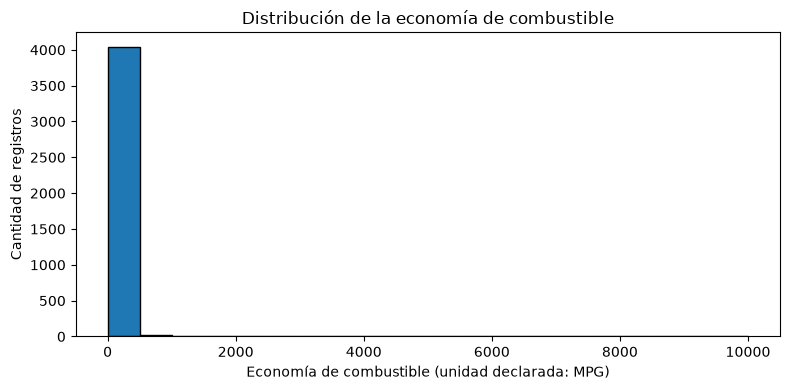

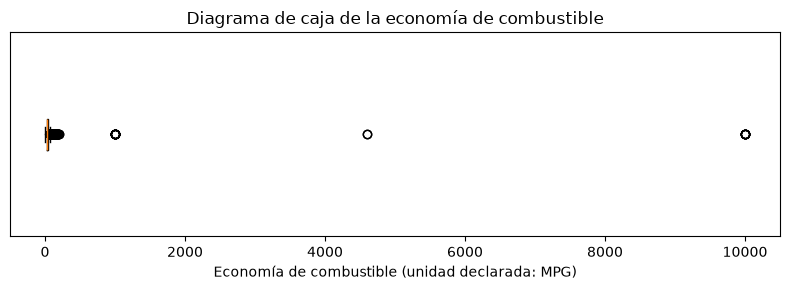

In [17]:
economia = datos["RND_ADJ_FE"].dropna()

display(economia.describe().round(2))

plt.figure(figsize=(8, 4))
plt.hist(economia, bins=20, edgecolor="black")
plt.title("Distribución de la economía de combustible")
plt.xlabel("Economía de combustible (unidad declarada: MPG)")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.boxplot(economia, orientation="horizontal", whis=1.5)
plt.title("Diagrama de caja de la economía de combustible")
plt.xlabel("Economía de combustible (unidad declarada: MPG)")
plt.yticks([])
plt.tight_layout()
plt.show()

### Análisis de la economía de combustible

La variable cuenta con 4066 valores disponibles y 221 faltantes. Su mediana es 32,9 MPG, y el 50 % central de los valores se encuentra entre 24,3 y 43,7 MPG. La media, de 64,96 MPG, es considerablemente mayor que la mediana debido a la influencia de los valores elevados.
El límite superior del criterio intercuartílico es aproximadamente 72,8 MPG. Se observan valores que lo superan, incluido un máximo cercano a 10000 MPG. Estos extremos amplían la escala de ambos gráficos y comprimen visualmente la mayor parte de las observaciones, dificultando distinguir su distribución.
El valor cercano a 10000 requiere consultar la documentación y revisar los registros correspondientes para determinar si representa una medición o una codificación especial. El mínimo de 0 MPG también requiere interpretación, aunque el criterio del boxplot no lo marque como atípico.
Además, la distribución reúne diferentes combustibles y categorías de ensayo. Por ello, un valor elevado respecto del conjunto no implica necesariamente una anomalía dentro del grupo al que pertenece.

### Conclusión general

La exploración permitió describir las distribuciones e identificar observaciones que requieren revisión. Los registros se conservan sin modificaciones: cualquier decisión posterior de limpieza deberá fundamentarse en la documentación y en el contexto de los ensayos, además de los criterios estadísticos utilizados.

### Valores Atipicos

Los registros identificados se examinan junto con el modelo, el combustible y el procedimiento de ensayo, siguiendo el contexto proporcionado por la metadata. 
También se revisan valores que resultaron llamativos durante la exploración.

## 2. Limpieza de la base

### 2.1. Preparación de la copia de trabajo

Creamos `datos_limpios` como una copia de `datos` para hacer la limpieza sin cambiar la base original. Importamos NumPy para poder usar `np.nan`, que representa un valor faltante.

Quitamos diez columnas de esta copia. `Model Year` y `FE_UNIT` tienen el mismo valor en todas las filas. Las otras ocho contienen códigos cuya información también aparece en columnas con descripciones; conservamos esas descripciones para facilitar la lectura.

Al final mostramos el tamaño de ambas bases: la original tiene 67 columnas y la copia queda con 57. Las dos mantienen las 4.287 filas.

In [14]:
import numpy as np

datos_limpios = datos.copy()

columnas_excluir = [
    'Model Year',
    'FE_UNIT',
    'Tested Transmission Type Code',
    'Drive System Code',
    'Transmission Overdrive Code',
    'Shift Indicator Light Use Cd',
    'Test Procedure Cd',
    'Test Fuel Type Cd',
    'Aftertreatment Device Cd',
    'Averaging Method Cd'
]

datos_limpios = datos_limpios.drop(columns=columnas_excluir)
print('Dimensiones originales:', datos.shape)
print('Dimensiones de trabajo:', datos_limpios.shape)

Dimensiones originales: (4287, 67)
Dimensiones de trabajo: (4287, 57)


### 2.2. Comprobación de los registros

Comprobamos si hay filas iguales en todas sus columnas y contamos cuántas configuraciones y números de test distintos siguen presentes. `clave_config` reúne las tres columnas que usamos en el punto 1 para reconocer cada configuración.

El resultado muestra cero filas completamente duplicadas, 1.448 configuraciones y 4.014 números de test distintos. Este bloque solo cuenta y muestra resultados: no elimina filas. Que se repita un número de test no significa que toda la fila esté duplicada.

In [15]:
print('Filas completamente duplicadas:', datos_limpios.duplicated().sum())
print('Configuraciones conservadas:', datos_limpios[clave_config].drop_duplicates().shape[0])
print('Números de test conservados:', len(datos_limpios['Test Number'].value_counts()))

Filas completamente duplicadas: 0
Configuraciones conservadas: 1448
Números de test conservados: 4014


### 2.3. Reemplazo de los valores seleccionados por faltantes

Reemplazamos por `NaN` los valores que seleccionamos para la limpieza: cilindrada de 99,999 L, potencia de 1 HP y economías de 9999,9999999; 4595,3; 4599,1 y cero. `replace()` busca esos valores en cada columna y los cambia por un faltante.

La última línea hace lo mismo con los 68 valores de economía señalados por el diagrama de caja del punto 1. `atipicos.index` permite ubicar las filas correspondientes en la copia. Estos casos pertenecen al grupo de gasolina Tier 2 y al procedimiento federal de dos días que analizamos antes.

Estar fuera de los límites del diagrama no demuestra que un dato sea incorrecto. En esta versión decidimos dejarlos como faltantes para los análisis siguientes; esta decisión queda sujeta a revisión del grupo. Se reemplaza el valor de economía, pero se conserva el resto de cada fila. Los faltantes que ya existían permanecen sin completar.

In [16]:
datos_limpios['Test Veh Displacement (L)'] = datos_limpios['Test Veh Displacement (L)'].replace(99.999, np.nan)
datos_limpios['Rated Horsepower'] = datos_limpios['Rated Horsepower'].replace(1, np.nan)
datos_limpios['RND_ADJ_FE'] = datos_limpios['RND_ADJ_FE'].replace(
    [9999.9999999, 4595.3, 4599.1, 0], np.nan
)
datos_limpios.loc[atipicos.index, 'RND_ADJ_FE'] = np.nan

### 2.4. Conclusión de la limpieza

La base de trabajo quedó con **4.287 filas y 57 columnas**. Se retiraron diez columnas y se conservaron todas las filas, las 1.448 configuraciones y los 4.014 números de test distintos. No se encontraron filas completamente duplicadas.

Se reemplazaron por `NaN` **183 valores**: 95 de cilindrada, 8 de potencia y 80 de economía de combustible. Estos últimos incluyen los 68 valores señalados por el diagrama de caja. La columna de economía pasó de 221 a 301 faltantes. Los faltantes que ya existían no se completaron.

Los reemplazos reflejan las decisiones adoptadas para esta versión y quedan sujetos a revisión del grupo: un valor señalado como atípico no es necesariamente un error. Los nuevos candidatos encontrados en el apartado 1.4, incluidos los 15 valores elevados de `PM (g/mi)`, siguen pendientes de revisión y no se modificaron.

La limpieza se realizó sobre `datos_limpios`; el archivo Excel y la base original `datos` se conservaron sin cambios.

## 3. Hipótesis propuestas

Pendiente de desarrollo. Se formularán una hipótesis univariada, una bivariada y una multivariada, con su justificación de dominio.

## 4. Validación de hipótesis

Pendiente de desarrollo. Se evaluarán las tres hipótesis propuestas y las tres indicadas en el enunciado. Para cada una se presentarán la técnica elegida, sus condiciones de aplicación, los resultados y la conclusión.